# Decision trees

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/03-supervised/decision-trees/decision-trees-notebook.ipynb)

Companion notebook for the *Decision trees* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn class that does the same job.

**Data:** the Iris flowers (150 flowers, 4 measurements, 3 species).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42

iris = load_iris()
X, y = iris.data, iris.target

## 1. Impurity of a node

With class shares $p_k$ in a node: Gini $G = 1 - \sum_k p_k^2$ and entropy $H = -\sum_k p_k \log_2 p_k$.

In [2]:
def gini(labels: np.ndarray) -> float:
    """Gini impurity of a set of labels."""
    shares = np.bincount(labels) / len(labels)
    return 1 - np.sum(shares**2)


def entropy(labels: np.ndarray) -> float:
    """Entropy in bits of a set of labels."""
    shares = np.bincount(labels) / len(labels)
    shares = shares[shares > 0]
    return -np.sum(shares * np.log2(shares))


print(f"all 150 flowers: Gini {gini(y):.3f}, entropy {entropy(y):.3f}")

all 150 flowers: Gini 0.667, entropy 1.585


In [3]:
stump = DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE).fit(X, y)
print("same Gini at the root:", np.isclose(gini(y), stump.tree_.impurity[0]))

same Gini at the root: True


## 2. The best first split

Try every feature and every threshold between two sorted values. Score a split by the
weighted Gini of the two sides, $\frac{n_L}{n}G_L + \frac{n_R}{n}G_R$, and keep the lowest.

In [4]:
best_score, best_feature, best_threshold = np.inf, None, None
for feature in range(X.shape[1]):
    values = np.unique(X[:, feature])
    for threshold in (values[:-1] + values[1:]) / 2:
        left = X[:, feature] <= threshold
        score = left.mean() * gini(y[left]) + (~left).mean() * gini(y[~left])
        if score < best_score:
            best_score, best_feature, best_threshold = score, feature, threshold

print(f"by hand: {iris.feature_names[best_feature]} <= {best_threshold:.2f}, weighted Gini {best_score:.3f}")

by hand: petal length (cm) <= 2.45, weighted Gini 0.333


In [5]:
left, right = stump.tree_.children_left[0], stump.tree_.children_right[0]
node_sizes, node_gini = stump.tree_.n_node_samples, stump.tree_.impurity
library_score = (node_sizes[left] * node_gini[left] + node_sizes[right] * node_gini[right]) / node_sizes[0]
print(f"scikit-learn: {iris.feature_names[stump.tree_.feature[0]]} <= {stump.tree_.threshold[0]:.2f}")
print("same weighted Gini:", np.isclose(best_score, library_score))

scikit-learn: petal length (cm) <= 2.45
same weighted Gini: True


Petal length and petal width both separate setosa perfectly, so the two may pick different
features with the same score.

## 3. Growing the tree

Repeating the best split on each side builds the tree. A leaf predicts the majority class.

test accuracy 0.978


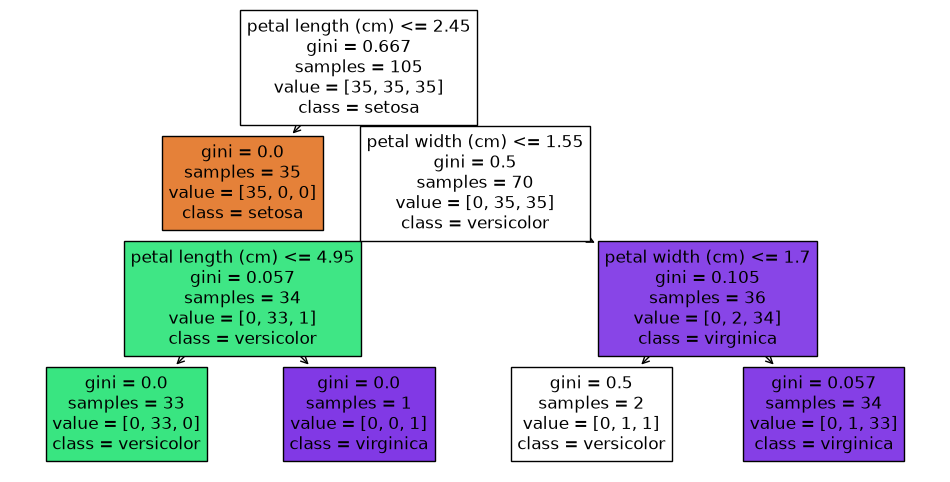

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
print(f"test accuracy {tree.score(X_test, y_test):.3f}")

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()

## Exercises

1. Use entropy instead of Gini in section 2 and compare with `DecisionTreeClassifier(criterion="entropy")`.
2. Train trees with `max_depth` from 1 to 8 and plot training and test accuracy.
3. Write the prediction of a depth-2 tree by hand with two `if` tests and compare it with `tree.predict`.